In [9]:
# ============================================================
# TRAVELTIDE – HOTELS INSPECTION
# ============================================================

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import shutil
from IPython.display import display

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 2. Define project directories
PROJECT_DIR = Path(
    r"D:\MSIT_Schulungsunterlagen\Projekte\TravelTide"
)

SOURCE_FILE = (
    PROJECT_DIR
    / "data"
    / "working"
    / "01_exploration"
    / "expl_hotels.csv"
)

CLEANING_DIR = (
    PROJECT_DIR
    / "data"
    / "working"
    / "02_inspection"
)

TARGET_FILE = CLEANING_DIR / "insp_hotels.csv"

# 3. Create cleaning directory
CLEANING_DIR.mkdir(parents=True, exist_ok=True)

# 4. Check source file
if not SOURCE_FILE.is_file():
    raise FileNotFoundError(
        f"Source file not found: {SOURCE_FILE}"
    )

# 5. Create cleaning copy
shutil.copy2(SOURCE_FILE, TARGET_FILE)

# 6. Load cleaning copy into DataFrame
hotels = pd.read_csv(TARGET_FILE)

# 7. Display loading report
print("=" * 60)
print("TRAVELTIDE – HOTELS INSPECTION")
print("=" * 60)

print(f"Source:  {SOURCE_FILE}")
print(f"Target:  {TARGET_FILE}")
print(f"Rows:    {hotels.shape[0]:,}")
print(f"Columns: {hotels.shape[1]}")
print("Status:  SUCCESS")
print("=" * 60)


TRAVELTIDE – HOTELS INSPECTION
Source:  D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\01_exploration\expl_hotels.csv
Target:  D:\MSIT_Schulungsunterlagen\Projekte\TravelTide\data\working\02_inspection\insp_hotels.csv
Rows:    1,918,617
Columns: 7
Status:  SUCCESS


In [10]:
# Allgemeine Informationen zum Datensatz
hotels.info()

# Statistische Zusammenfassung aller Spalten
display(hotels.describe(include="all").T)

# Anzahl fehlender Werte je Spalte
display(hotels.isnull().sum().to_frame("Missing Values"))
print("****")
type(hotels.isnull().sum().to_frame("Missing Values"))

# Anzahl doppelter Zeilen
print("Duplicate rows:", hotels.duplicated().sum())


<class 'pandas.DataFrame'>
RangeIndex: 1918617 entries, 0 to 1918616
Data columns (total 7 columns):
 #   Column              Dtype
---  ------              -----
 0   trip_id             str  
 1   hotel_name          str  
 2   nights              int64
 3   rooms               int64
 4   check_in_time       str  
 5   check_out_time      str  
 6   hotel_per_room_usd  int64
dtypes: int64(3), str(4)
memory usage: 102.5 MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
trip_id,1918617,1918617,1-240dcec347d74794a42f89db57252550,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotel_name,1918617,2798,Extended Stay - new york,14075,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nights,1918617.0,NaN,NaN,NaN,4.271452,4.488629,-2.0,1.0,3.0,6.0,107.0
rooms,1918617.0,NaN,NaN,NaN,1.189341,0.487965,0.0,1.0,1.0,1.0,6.0
check_in_time,1918617,1317413,2023-03-19 11:00:00,1190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
check_out_time,1918617,1221,2023-04-05 11:00:00,6410,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hotel_per_room_usd,1918617.0,NaN,NaN,NaN,177.305372,117.183371,8.0,99.0,148.0,222.0,2377.0


,Missing Values
trip_id,0
hotel_name,0
nights,0
rooms,0
check_in_time,0
check_out_time,0
hotel_per_room_usd,0


****
Duplicate rows: 0


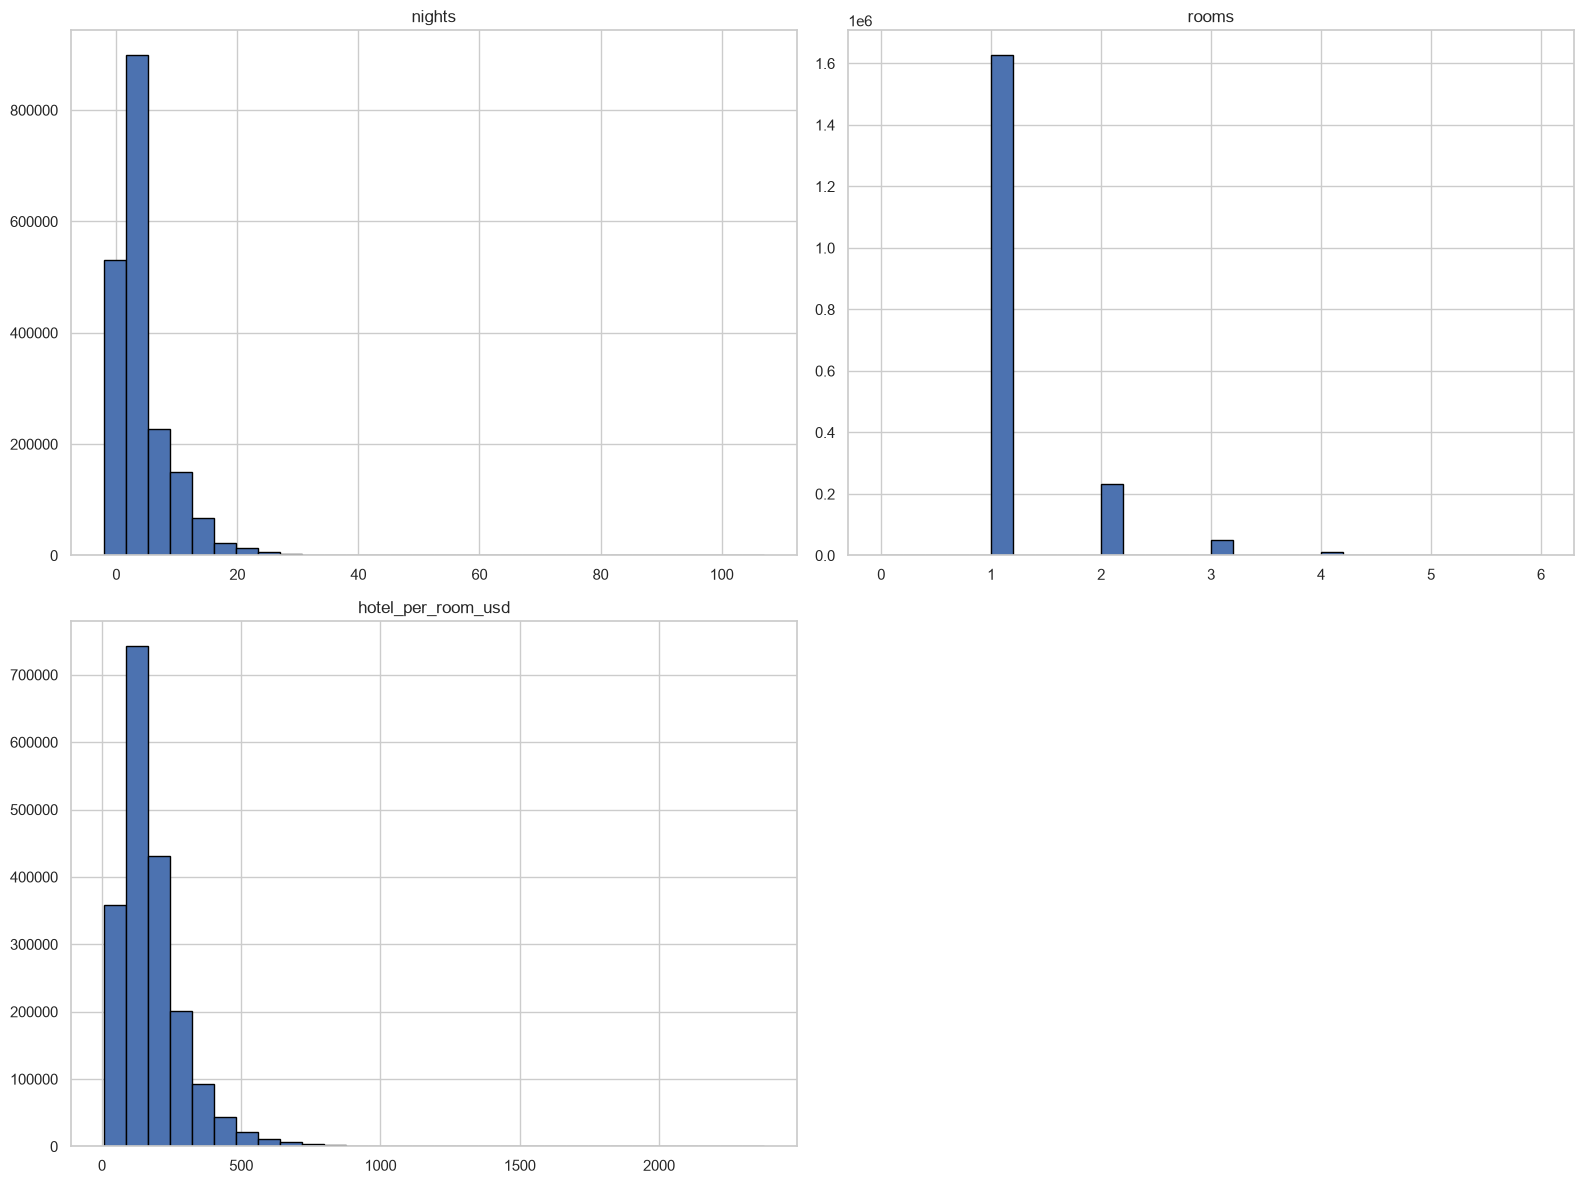

In [11]:
# Verteilung numerischer Variablen
hotels.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

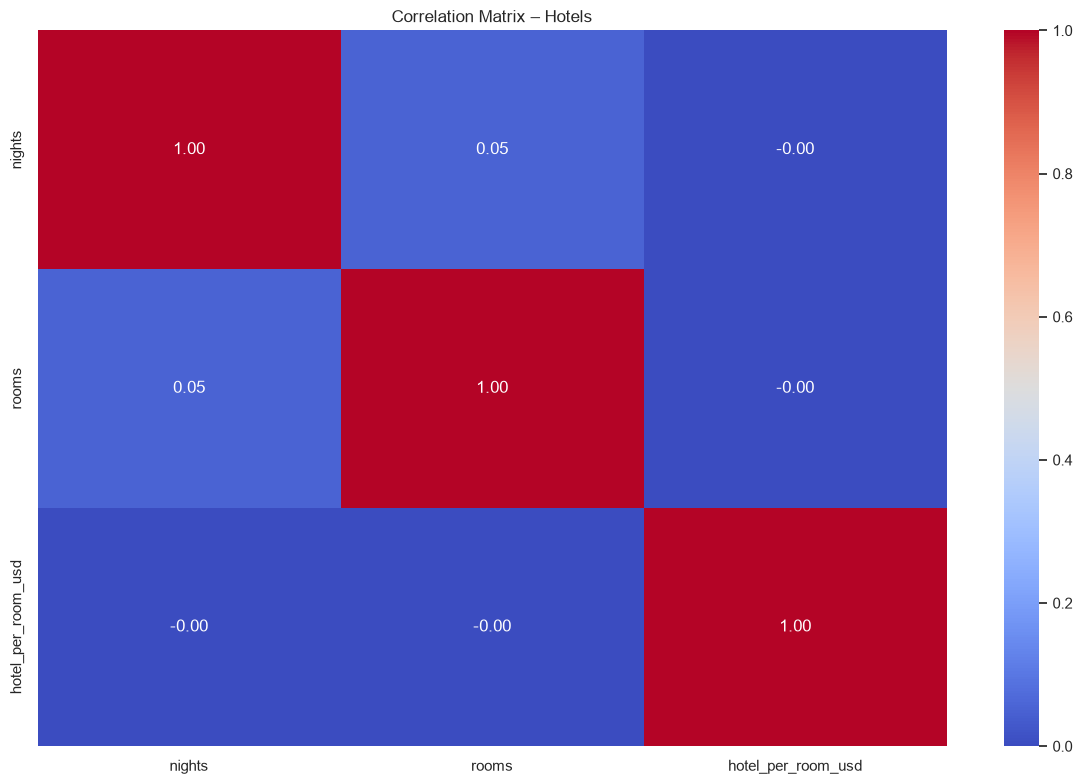

In [12]:
# Nur numerische Spalten berücksichtigen
numeric_flights = hotels.select_dtypes(include="number")

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_flights.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix – Hotels")
plt.tight_layout()
plt.show()
